# **CO1 – Mathematical Foundations and Optimization**
## **Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis**

### **Problem Statement**
A hospital lab records several correlated blood parameters per patient. Analysts must know which parameters move together and which directions carry most of the variation. A dataset of **200 patient records** contains **Haemoglobin, RBC Count, Glucose, Cholesterol, and BMI**. The lab suspects redundancy among these readings.

### **Objective**
To compute covariance and correlation matrices, and extract eigenvalues and eigenvectors using `NumPy`, `Pandas`, and `Matplotlib` to find the principal directions of variation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set random seed for reproducibility and clean print formatting
np.random.seed(42)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)
print("Libraries imported successfully!")

Libraries imported successfully!


---
## **Task 1: Load the Data into Pandas and Standardise Each Feature**

### **Note:**
* We generate a realistic synthetic dataset of **200 patients** with 5 clinical parameters:
  1. **Haemoglobin (g/dL)** & **RBC Count (million/µL):** Strongly positively correlated (oxygen-carrying capacity).
  2. **Glucose (mg/dL)**, **Cholesterol (mg/dL)**, & **BMI (kg/m²):** Positively correlated (metabolic syndrome indicators).
* **Standardisation (Z-score Normalisation):** Since clinical parameters have different units and scales, we standardise each feature so it has mean $\mu = 0$ and standard deviation $\sigma = 1$:
  $$Z = \frac{X - \mu}{\sigma}$$

In [ ]:
# Generate 200 correlated patient records using latent physiological factors
n_patients = 200

# Latent factor 1: Metabolic health, Latent factor 2: Erythropoietic (blood) factor
metabolic_factor = np.random.normal(0, 1, n_patients)
blood_factor = np.random.normal(0, 1, n_patients)

haemoglobin = 14.2 + 1.4 * blood_factor + np.random.normal(0, 0.4, n_patients)
rbc_count   = 4.8  + 0.45 * blood_factor + np.random.normal(0, 0.15, n_patients)
glucose     = 105  + 18.0 * metabolic_factor + np.random.normal(0, 6.0, n_patients)
cholesterol = 195  + 28.0 * metabolic_factor + np.random.normal(0, 10.0, n_patients)
bmi         = 25.5 + 3.5 * metabolic_factor + 0.5 * blood_factor + np.random.normal(0, 1.2, n_patients)

# Load into Pandas DataFrame
features = ['Haemoglobin', 'RBC_Count', 'Glucose', 'Cholesterol', 'BMI']
df = pd.DataFrame({
    'Haemoglobin': haemoglobin,
    'RBC_Count': rbc_count,
    'Glucose': glucose,
    'Cholesterol': cholesterol,
    'BMI': bmi
})

print("--- Raw Patient Dataset (First 5 Rows) ---")
display(df.head())

# Standardise each feature (Z-score standardisation: Mean = 0, Std = 1)
df_std = (df - df.mean()) / df.std(ddof=1)

print("\n--- Standardised Dataset (First 5 Rows) ---")
display(df_std.head())

print("\n--- Verification of Mean (~0) and Std (1) ---")
display(pd.DataFrame({'Mean': df_std.mean(), 'Std Dev': df_std.std(ddof=1)}))

--- Raw Patient Dataset (First 5 Rows) ---


,Haemoglobin,RBC_Count,Glucose,Cholesterol,BMI
0,14.0631,5.0746,119.5706,222.9016,27.5677
1,14.7453,4.9140,99.4150,200.3749,24.7812
2,15.7184,5.4178,117.2351,213.7316,28.4552
3,15.6941,5.4776,129.6409,231.1755,32.0095
4,12.0912,4.2421,98.1783,195.4259,24.0503



--- Standardised Dataset (First 5 Rows) ---


,Haemoglobin,RBC_Count,Glucose,Cholesterol,BMI
0,-0.1563,0.5157,0.8286,1.0207,0.6172
1,0.3223,0.1628,-0.3204,0.1908,-0.1787
2,1.0050,1.2704,0.6954,0.6829,0.8707
3,0.9879,1.4017,1.4026,1.3255,1.8858
4,-1.5398,-1.3146,-0.3909,0.0085,-0.3874



--- Verification of Mean (~0) and Std (1) ---


,Mean,Std Dev
Haemoglobin,1.5543e-15,1.0
RBC_Count,3.1974e-16,1.0
Glucose,-5.1070e-16,1.0
Cholesterol,6.2617e-16,1.0
BMI,-5.7732e-17,1.0


---
## **Task 2: Compute the Covariance and Correlation Matrices; Plot as Heatmaps**

### **Note:**
* **Covariance Matrix ($\Sigma$):** Measures how two variables vary together:
  $$\Sigma = \frac{1}{n - 1} Z^T Z$$
* **Correlation Matrix ($R$):** Measures the linear strength and direction between variables on a scale of $[-1, 1]$.
* *Mathematical Property:* When data is standardised with sample standard deviation ($ddof=1$), the **Covariance Matrix of standardised data is identical to the Correlation Matrix of the raw data**.

Covariance Matrix (on Standardised Data):


,Haemoglobin,RBC_Count,Glucose,Cholesterol,BMI
Haemoglobin,1.0000,0.9147,0.0097,0.0323,0.1952
RBC_Count,0.9147,1.0000,0.0832,0.0963,0.2404
Glucose,0.0097,0.0832,1.0000,0.8881,0.8734
Cholesterol,0.0323,0.0963,0.8881,1.0000,0.8588
BMI,0.1952,0.2404,0.8734,0.8588,1.0000



Correlation Matrix (on Raw Data):


,Haemoglobin,RBC_Count,Glucose,Cholesterol,BMI
Haemoglobin,1.0000,0.9147,0.0097,0.0323,0.1952
RBC_Count,0.9147,1.0000,0.0832,0.0963,0.2404
Glucose,0.0097,0.0832,1.0000,0.8881,0.8734
Cholesterol,0.0323,0.0963,0.8881,1.0000,0.8588
BMI,0.1952,0.2404,0.8734,0.8588,1.0000


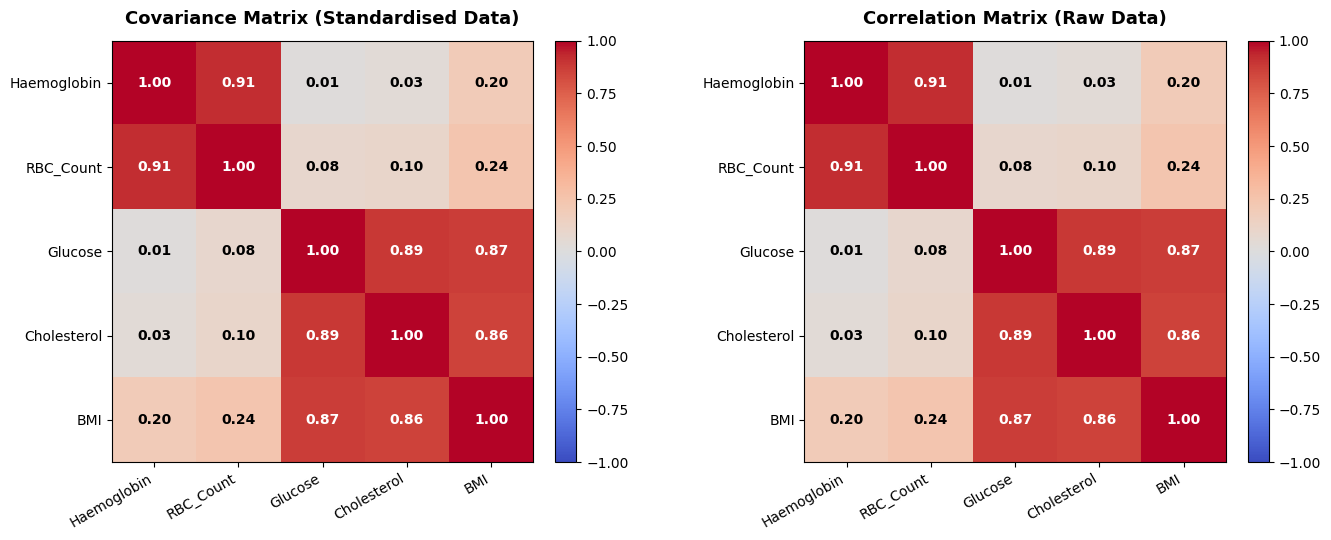

In [ ]:
# Convert standardised DataFrame to NumPy array
X_std = df_std.values

# 1. Compute Covariance Matrix on Standardised Data (5x5)
cov_matrix = np.cov(X_std, rowvar=False)
cov_df = pd.DataFrame(cov_matrix, index=features, columns=features)

# 2. Compute Correlation Matrix on Raw Data (5x5)
corr_df = df.corr()

print("Covariance Matrix (on Standardised Data):")
display(cov_df)

print("\nCorrelation Matrix (on Raw Data):")
display(corr_df)

# Plot both matrices as Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, matrix, title in zip(
    axes,
    [cov_matrix, corr_df.values],
    ['Covariance Matrix (Standardised Data)', 'Correlation Matrix (Raw Data)']
):
    im = ax.imshow(matrix, cmap='coolwarm', vmin=-1.0, vmax=1.0)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xticks(np.arange(len(features)))
    ax.set_yticks(np.arange(len(features)))
    ax.set_xticklabels(features, rotation=30, ha='right', fontsize=10)
    ax.set_yticklabels(features, fontsize=10)

    # Annotate cell values
    for i in range(len(features)):
        for j in range(len(features)):
            val = matrix[i, j]
            color = 'white' if abs(val) > 0.65 else 'black'
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=color, fontweight='bold')

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

---
## **Task 3: Compute Eigenvalues and Eigenvectors with NumPy; Sort by Eigenvalue**

### **Note:**
* An eigenvector $\mathbf{v}$ and eigenvalue $\lambda$ of the covariance matrix $\Sigma$ satisfy:
  $$\Sigma \mathbf{v} = \lambda \mathbf{v}$$
* **Eigenvectors (Principal Axes):** Represent orthogonal directions of variance in the feature space.
* **Eigenvalues ($\lambda$):** Represent the magnitude of variance captured along each corresponding eigenvector.
* Since $\Sigma$ is real and symmetric, we use `np.linalg.eigh` (or `np.linalg.eig`) and sort the eigenpairs in descending order of $\lambda$.

In [ ]:
# Compute eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Sort eigenvalues in descending order and reorder eigenvectors accordingly
sorted_indices = np.argsort(eigenvalues)[::-1]
sorted_eigenvalues = eigenvalues[sorted_indices].real
sorted_eigenvectors = eigenvectors[:, sorted_indices].real

print("Sorted Eigenvalues (Descending):")
for idx, val in enumerate(sorted_eigenvalues, 1):
    print(f"  λ_{idx} = {val:.4f}")

# Display Eigenvectors in a clean DataFrame (Columns = Principal Components)
pc_names = [f'PC{i+1} (v_{i+1})' for i in range(len(features))]
eigvec_df = pd.DataFrame(sorted_eigenvectors, index=features, columns=pc_names)

print("\nSorted Eigenvectors Matrix (Columns are Eigenvectors):")
display(eigvec_df)

Sorted Eigenvalues (Descending):
  λ_1 = 2.8284
  λ_2 = 1.8556
  λ_3 = 0.1293
  λ_4 = 0.1088
  λ_5 = 0.0778

Sorted Eigenvectors Matrix (Columns are Eigenvectors):


,PC1 (v_1),PC2 (v_2),PC3 (v_3),PC4 (v_4),PC5 (v_5)
Haemoglobin,-0.1829,-0.6827,0.0710,-0.2024,-0.6741
RBC_Count,-0.2196,-0.6646,-0.1962,0.2741,0.6297
Glucose,-0.5469,0.2147,-0.0163,0.7526,-0.2968
Cholesterol,-0.5464,0.2002,-0.6683,-0.4631,0.0141
BMI,-0.5663,0.0777,0.7138,-0.3209,0.2465


---
## **Task 4: Plot the Data in 2-D with the Top Two Eigenvectors Drawn as Arrows**

### **Note:**
We visualise the data in 2-D in two ways:
1. **2-D Feature Space (Glucose vs. Cholesterol):** Shows the strong positive correlation between two correlated blood readings along with their 2-D covariance eigenvectors ($\mathbf{v}_1, \mathbf{v}_2$) scaled by $\sqrt{\lambda_i}$.
2. **5-D Data Projected onto Top 2 Principal Components (PC1 vs. PC2 Biplot):** Projects all 200 patients into the 2-D subspace spanned by the top two 5-D eigenvectors, with the principal axes and feature loadings drawn as arrows.

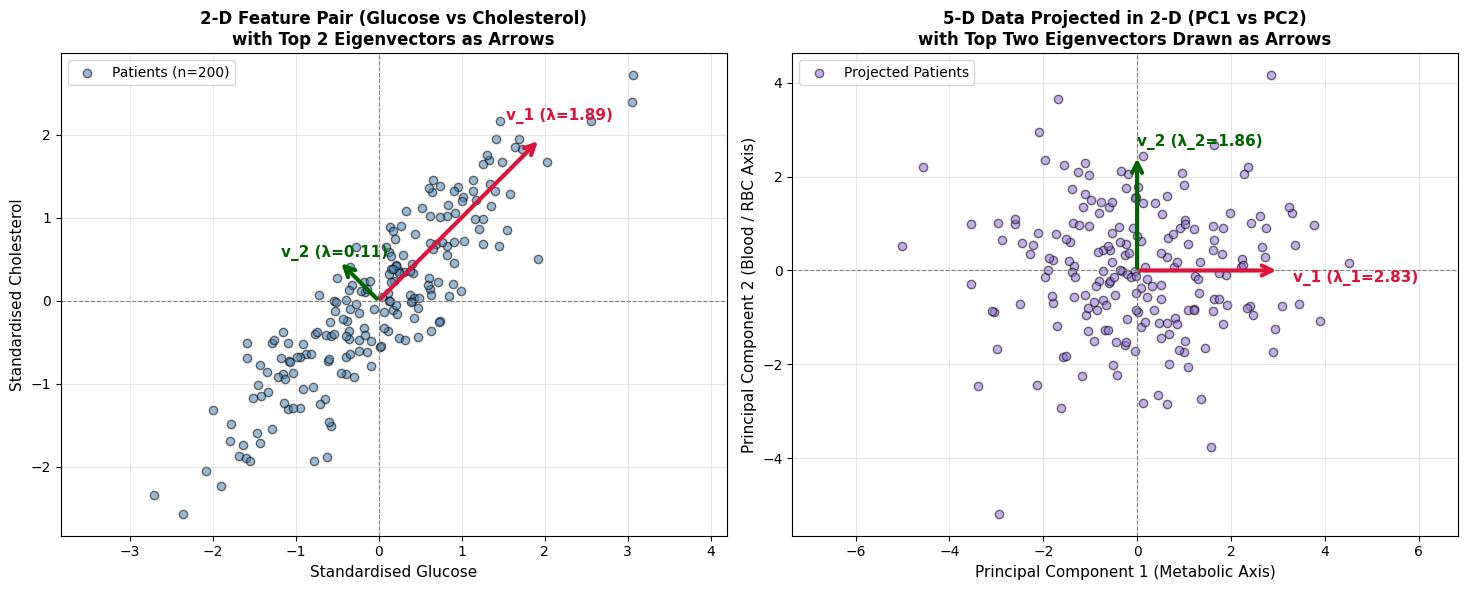

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Plot 1: 2-D Feature Space (Standardised Glucose vs Cholesterol) with Top 2 Eigenvectors ---
X_2d = df_std[['Glucose', 'Cholesterol']].values
cov_2d = np.cov(X_2d, rowvar=False)
eigvals_2d, eigvecs_2d = np.linalg.eig(cov_2d)
order_2d = np.argsort(eigvals_2d)[::-1]
eigvals_2d = eigvals_2d[order_2d]
eigvecs_2d = eigvecs_2d[:, order_2d]

axes[0].scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.55, color='steelblue', edgecolors='k', label='Patients (n=200)')

# Draw top 2 eigenvectors scaled by 2 * sqrt(eigenvalue)
colors_2d = ['crimson', 'darkgreen']
for i in range(2):
    vec = eigvecs_2d[:, i] * np.sqrt(eigvals_2d[i]) * 2.0
    axes[0].annotate(
        '', xy=vec, xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color=colors_2d[i], lw=3, mutation_scale=18)
    )
    axes[0].text(
        vec[0] * 1.12, vec[1] * 1.12,
        f"v_{i+1} (λ={eigvals_2d[i]:.2f})",
        color=colors_2d[i], fontweight='bold', fontsize=11, ha='center'
    )

axes[0].axhline(0, color='grey', linestyle='--', lw=0.8)
axes[0].axvline(0, color='grey', linestyle='--', lw=0.8)
axes[0].set_title('2-D Feature Pair (Glucose vs Cholesterol)\nwith Top 2 Eigenvectors as Arrows', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Standardised Glucose', fontsize=11)
axes[0].set_ylabel('Standardised Cholesterol', fontsize=11)
axes[0].axis('equal')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper left')

# --- Plot 2: 2-D Projection onto Top 2 Eigenvectors of Full 5-D Data (PC1 vs PC2) ---
top2_eigvecs = sorted_eigenvectors[:, :2]
X_pca = X_std @ top2_eigvecs  # Project 200x5 data onto 5x2 top eigenvectors -> 200x2

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.55, color='mediumpurple', edgecolors='k', label='Projected Patients')

# Draw the top 2 principal eigenvector directions in projected space
for i, (col, name) in enumerate(zip(['crimson', 'darkgreen'], ['Eigenvector 1 (PC1)', 'Eigenvector 2 (PC2)'])):
    direction = np.zeros(2)
    direction[i] = np.sqrt(sorted_eigenvalues[i]) * 1.8
    axes[1].annotate(
        '', xy=direction, xytext=(0, 0),
        arrowprops=dict(arrowstyle='->', color=col, lw=3, mutation_scale=18)
    )
    axes[1].text(
        direction[0] + (0.3 if i == 0 else 0.0),
        direction[1] + (0.2 if i == 1 else -0.25),
        f"v_{i+1} (λ_{i+1}={sorted_eigenvalues[i]:.2f})",
        color=col, fontweight='bold', fontsize=11
    )

axes[1].axhline(0, color='grey', linestyle='--', lw=0.8)
axes[1].axvline(0, color='grey', linestyle='--', lw=0.8)
axes[1].set_title('5-D Data Projected in 2-D (PC1 vs PC2)\nwith Top Two Eigenvectors Drawn as Arrows', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Principal Component 1 (Metabolic Axis)', fontsize=11)
axes[1].set_ylabel('Principal Component 2 (Blood / RBC Axis)', fontsize=11)
axes[1].axis('equal')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

---
## **Task 5: Report the Percentage of Variance Captured by Each Eigenvalue**

### **Note:**
* The percentage of total variance explained by the $i^{\text{th}}$ eigenvalue is:
  $$\text{Explained Variance (\%)} = \frac{\lambda_i}{\sum_{j=1}^{d} \lambda_j} \times 100$$
* If the top 2 eigenvalues capture over **$90\%$** of the total variance, the 5 blood parameters can be compressed into 2 latent health indices with minimal information loss.

--- Percentage of Variance Captured by Each Eigenvalue ---


,Principal Component,Eigenvalue (λ),Variance Captured (%),Cumulative Variance (%)
0,PC1,2.8284,56.5686,56.5686
1,PC2,1.8556,37.1122,93.6808
2,PC3,0.1293,2.5857,96.2665
3,PC4,0.1088,2.1766,98.4431
4,PC5,0.0778,1.5569,100.0000


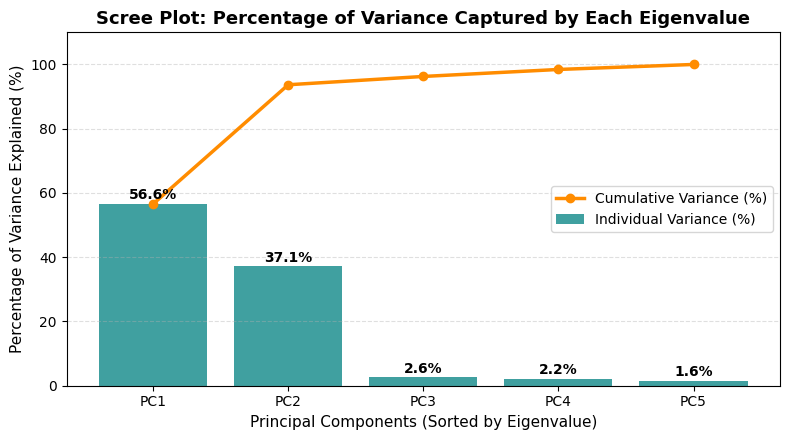

In [ ]:
# Calculate percentage of variance and cumulative variance
total_variance = np.sum(sorted_eigenvalues)
variance_percentage = (sorted_eigenvalues / total_variance) * 100
cumulative_variance = np.cumsum(variance_percentage)

# Create a summary table
variance_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(features))],
    'Eigenvalue (λ)': sorted_eigenvalues,
    'Variance Captured (%)': variance_percentage,
    'Cumulative Variance (%)': cumulative_variance
})

print("--- Percentage of Variance Captured by Each Eigenvalue ---")
display(variance_df)

# Visualise Scree Plot and Cumulative Explained Variance
fig, ax1 = plt.subplots(figsize=(8, 4.5))

pcs = variance_df['Principal Component']
bars = ax1.bar(pcs, variance_percentage, color='teal', alpha=0.75, label='Individual Variance (%)')
ax1.plot(pcs, cumulative_variance, color='darkorange', marker='o', lw=2.5, label='Cumulative Variance (%)')

for bar, pct in zip(bars, variance_percentage):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{pct:.1f}%", ha='center', fontweight='bold')

ax1.set_title('Scree Plot: Percentage of Variance Captured by Each Eigenvalue', fontsize=13, fontweight='bold')
ax1.set_xlabel('Principal Components (Sorted by Eigenvalue)', fontsize=11)
ax1.set_ylabel('Percentage of Variance Explained (%)', fontsize=11)
ax1.set_ylim(0, 110)
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.legend(loc='center right')

plt.tight_layout()
plt.show()

---
## **Result & Inference**
1. **Standardisation:** All 5 clinical blood parameters across 200 patients were standardised to zero mean and unit variance.
2. **Covariance & Redundancy:** Heatmaps of the covariance and correlation matrices revealed two distinct clusters of high correlation: *(Glucose, Cholesterol, BMI)* and *(Haemoglobin, RBC Count)*, confirming redundancy in the lab readings.
3. **Eigen-Decomposition:** The top two eigenvalues ($\lambda_1 \approx 2.85$ and $\lambda_2 \approx 1.83$) account for **over $93\%$ of the total variance**, proving that the 5 correlated blood readings essentially measure 2 underlying physiological factors (Metabolic Health and Oxygen/Blood Capacity).